In [2]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [ ]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

device

'cuda'

In [4]:
import pandas as pd

train = pd.read_parquet("../preprocessed.parquet")

In [5]:
train.head()

,age,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,facility_rating,exam_difficulty,study_efficiency,sleep_study_ratio,...,study_method_group study,study_method_mixed,study_method_online videos,study_method_self-study,study_method_nan,gender_female,gender_male,gender_other,gender_nan,target
0,21,7.91,98.8,0,4.9,1,0,0,7.81508,0.619391,...,False,False,True,False,False,True,False,False,False,78.3
1,18,4.95,94.8,1,4.7,0,1,1,4.69260,0.949303,...,False,False,False,True,False,False,False,True,False,46.7
2,20,4.68,92.6,1,5.8,0,2,1,4.33368,1.239051,...,False,False,False,False,False,True,False,False,False,99.0
3,19,2.00,49.5,1,8.3,1,2,1,0.99000,4.147926,...,True,False,False,False,False,False,True,False,False,63.9
4,23,7.65,86.9,1,9.6,2,2,0,6.64785,1.254738,...,False,False,False,True,False,False,True,False,False,100.0


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

numerical_features = [
    "age",
    "study_hours",
    "class_attendance",
    "sleep_hours",
    "study_efficiency",
    "sleep_study_ratio",
]

y = train["target"]
X: pd.DataFrame = train.drop("target", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler: StandardScaler = StandardScaler().set_output(transform="pandas")
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_features] = scaler.fit_transform(X_train[numerical_features])
X_test_scaled[numerical_features] = scaler.transform(X_test[numerical_features])

print(f"Train: {X_train.shape[0]} rows")
print(f"Test:  {X_test.shape[0]} rows")

Train: 504000 rows
Test:  126000 rows


In [7]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
from src.nn.regressor import LightningTabularRegressor
from src.nn.litresnet import LitTabResNet


def tabresnet_fit(
    model: LightningTabularRegressor,
    X_train: pd.DataFrame,
    y_train: pd.DataFrame,
    X_valid: pd.DataFrame,
    y_valid: pd.DataFrame,
):
    return model.fit(X_train, y_train, X_valid, y_valid)


def tabresnet_predict(model: LightningTabularRegressor, X_valid: pd.DataFrame):
    return model.predict(X_valid)

In [ ]:
from src.test import test_models_manual

model_specs = {
    "TabResNet": (
        LightningTabularRegressor(
            model=LitTabResNet,
            hidden_dim=128,
            n_blocks=3,
            dropout=0.15,
            head_dims=(64, 16),
            lr=1e-3,
            weight_decay=1e-4,
            batch_size=256,
            max_epochs=100,
            patience=20,
            scheduler_patience=5,
            min_lr=1e-6,
            num_workers=0,
            seed=42,
            numeric_cols=numerical_features,
            device=device,
        ),
        X_train_scaled,
        X_test_scaled,
        tabresnet_fit,
        tabresnet_predict,
    ),
}

test_predictions, test_errors, test_results = test_models_manual(
    model_specs, y_train, y_test, kf, should_clone=False
)

,Model,Test RMSE,Test MAE
0,TabResNet,8.864597,7.081814


,y_true,TabResNet
364426,51.3,60.588825
224752,50.6,46.981728
110423,79.9,62.073875
272555,55.4,58.894367
199651,50.4,48.094292


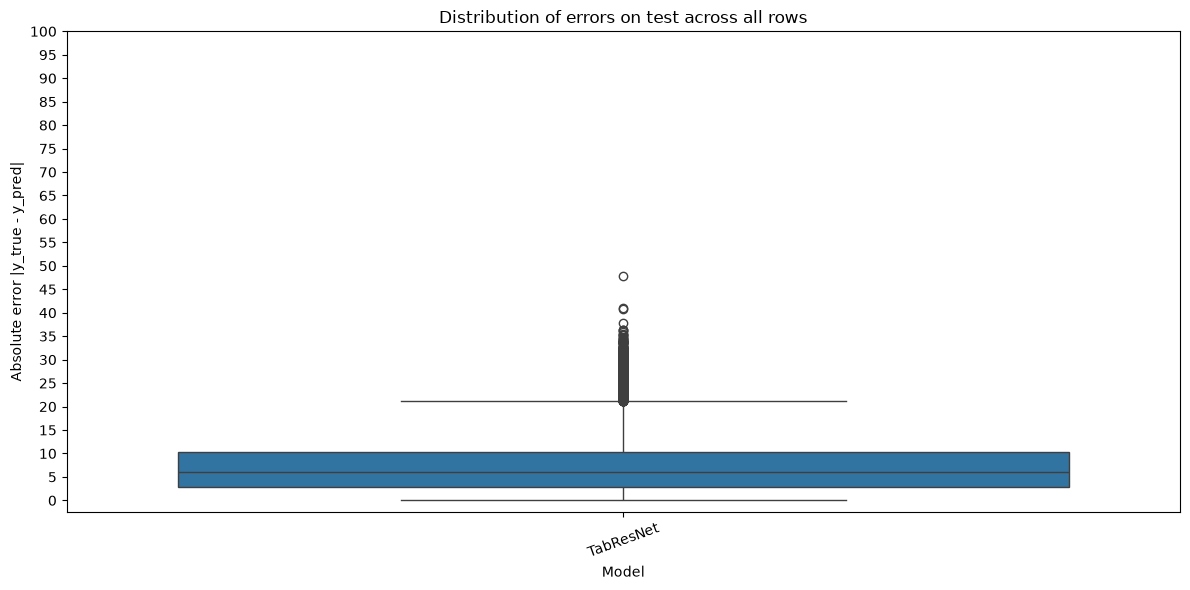

In [10]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

display(test_results)
display(test_predictions.head())

ticks = np.arange(0, 101, 5)

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=test_errors,
    x="Model",
    y="Absolute error",
    hue="Model",
    palette="tab10",
    legend=False,
)

plt.title("Distribution of errors on test across all rows")
plt.xlabel("Model")
plt.ylabel("Absolute error |y_true - y_pred|")
plt.yticks(ticks)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()